# DSCI 552 HW 6
Caitlyn Chan

In [3]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve, accuracy_score
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
RANDOM_STATE = 552

## tree-based methods

### 1a. load APS failure data

In [4]:
train = pd.read_csv(“../data/aps_failure_training_set.csv”, skiprows=20, na_values=“na”)
test = pd.read_csv(“../data/aps_failure_test_set.csv”, skiprows=20, na_values=“na”)

features = [c for c in train.columns if c != "class"]
y_train = (train["class"] == "pos").astype(int)
y_test = (test["class"] == "pos").astype(int)

print("train:", train.shape, "test:", test.shape, "features:", len(features))

train: (60000, 171) test: (16000, 171) features: 170


### 1b. data preparation

i. missing value techniques

Common data imputation techniques:
- deleting rows or columns with missing values (usually a threshold for data size for this technique to be okay)
- filling with a simple statistic: mean, median, or mode
- KNN imputation: fill with the average of the most similar rows
- iterative/regression imputation (ex.MICE): predict each missing feature from the others
- adding a "was missing" indicator column alongside one of the above

I use median imputation, since the features here are very skewed and the median isn't pulled around by outliers.

In [5]:
missing_pct = train[features].isna().mean().sort_values(ascending=False)
print("features with missing values:", (missing_pct > 0).sum(), "of", len(features))
print("rows with at least one missing value:", train[features].isna().any(axis=1).sum(), "of", len(train))
print(missing_pct.head(10).round(3))

features with missing values: 169 of 170
rows with at least one missing value: 59409 of 60000
br_000    0.821
bq_000    0.812
bp_000    0.796
bo_000    0.772
ab_000    0.772
cr_000    0.772
bn_000    0.733
bm_000    0.659
bl_000    0.455
bk_000    0.384
dtype: float64


In [6]:
X_train = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(train[features]), columns=features)
X_test = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(test[features]), columns=features)
print("missing values left:", X_train.isna().sum().sum() + X_test.isna().sum().sum())

missing values left: 0


ii. coefficient of variation

In [7]:
cv = (X_train.std(ddof=1) / X_train.mean()).sort_values(ascending=False)
cv_table = cv.rename("CV").to_frame()
with pd.option_context("display.max_rows", 200):
    display(cv_table)

,CV
cf_000,244.887517
co_000,244.507385
ad_000,244.322816
cs_009,237.930554
dh_000,123.216097
dj_000,117.494225
ag_000,92.917755
as_000,87.332500
ay_009,84.733735
ak_000,80.424975


iii. correlation matrix

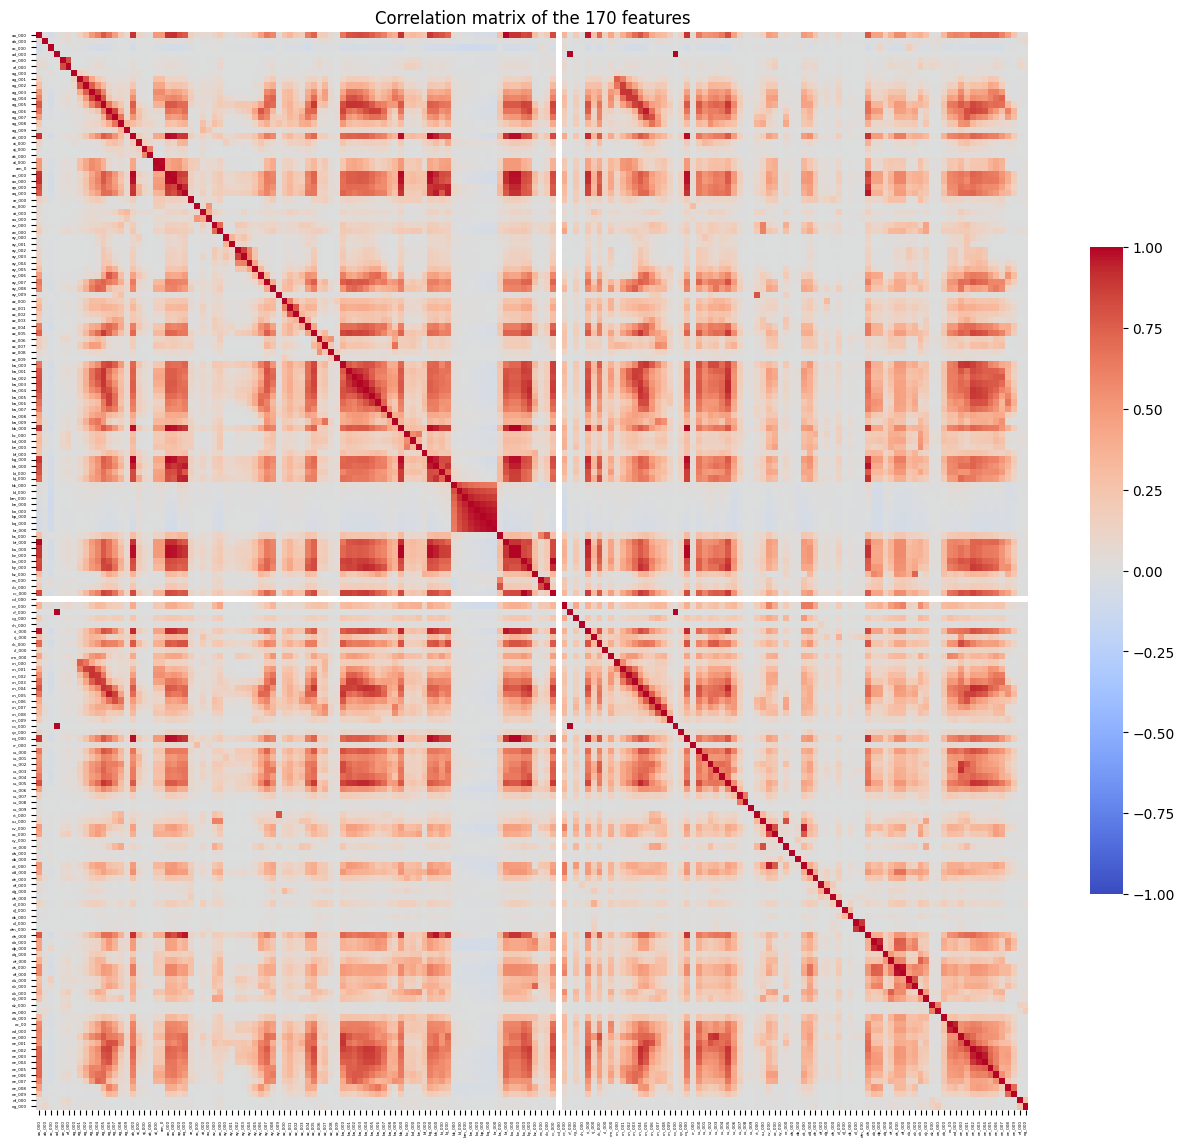

In [8]:
corr = X_train.corr()

plt.figure(figsize=(16, 14))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True, cbar_kws={"shrink": 0.6})
plt.xticks(fontsize=3); plt.yticks(fontsize=3)
plt.title("Correlation matrix of the 170 features")
plt.show()

iv. top ⌊√170⌋ = 13 features by CV,  scatter and box plots

In [9]:
k = int(np.floor(np.sqrt(170)))
top_cv = cv.dropna().index[:k].tolist()
print(k, "features:", top_cv)

13 features: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


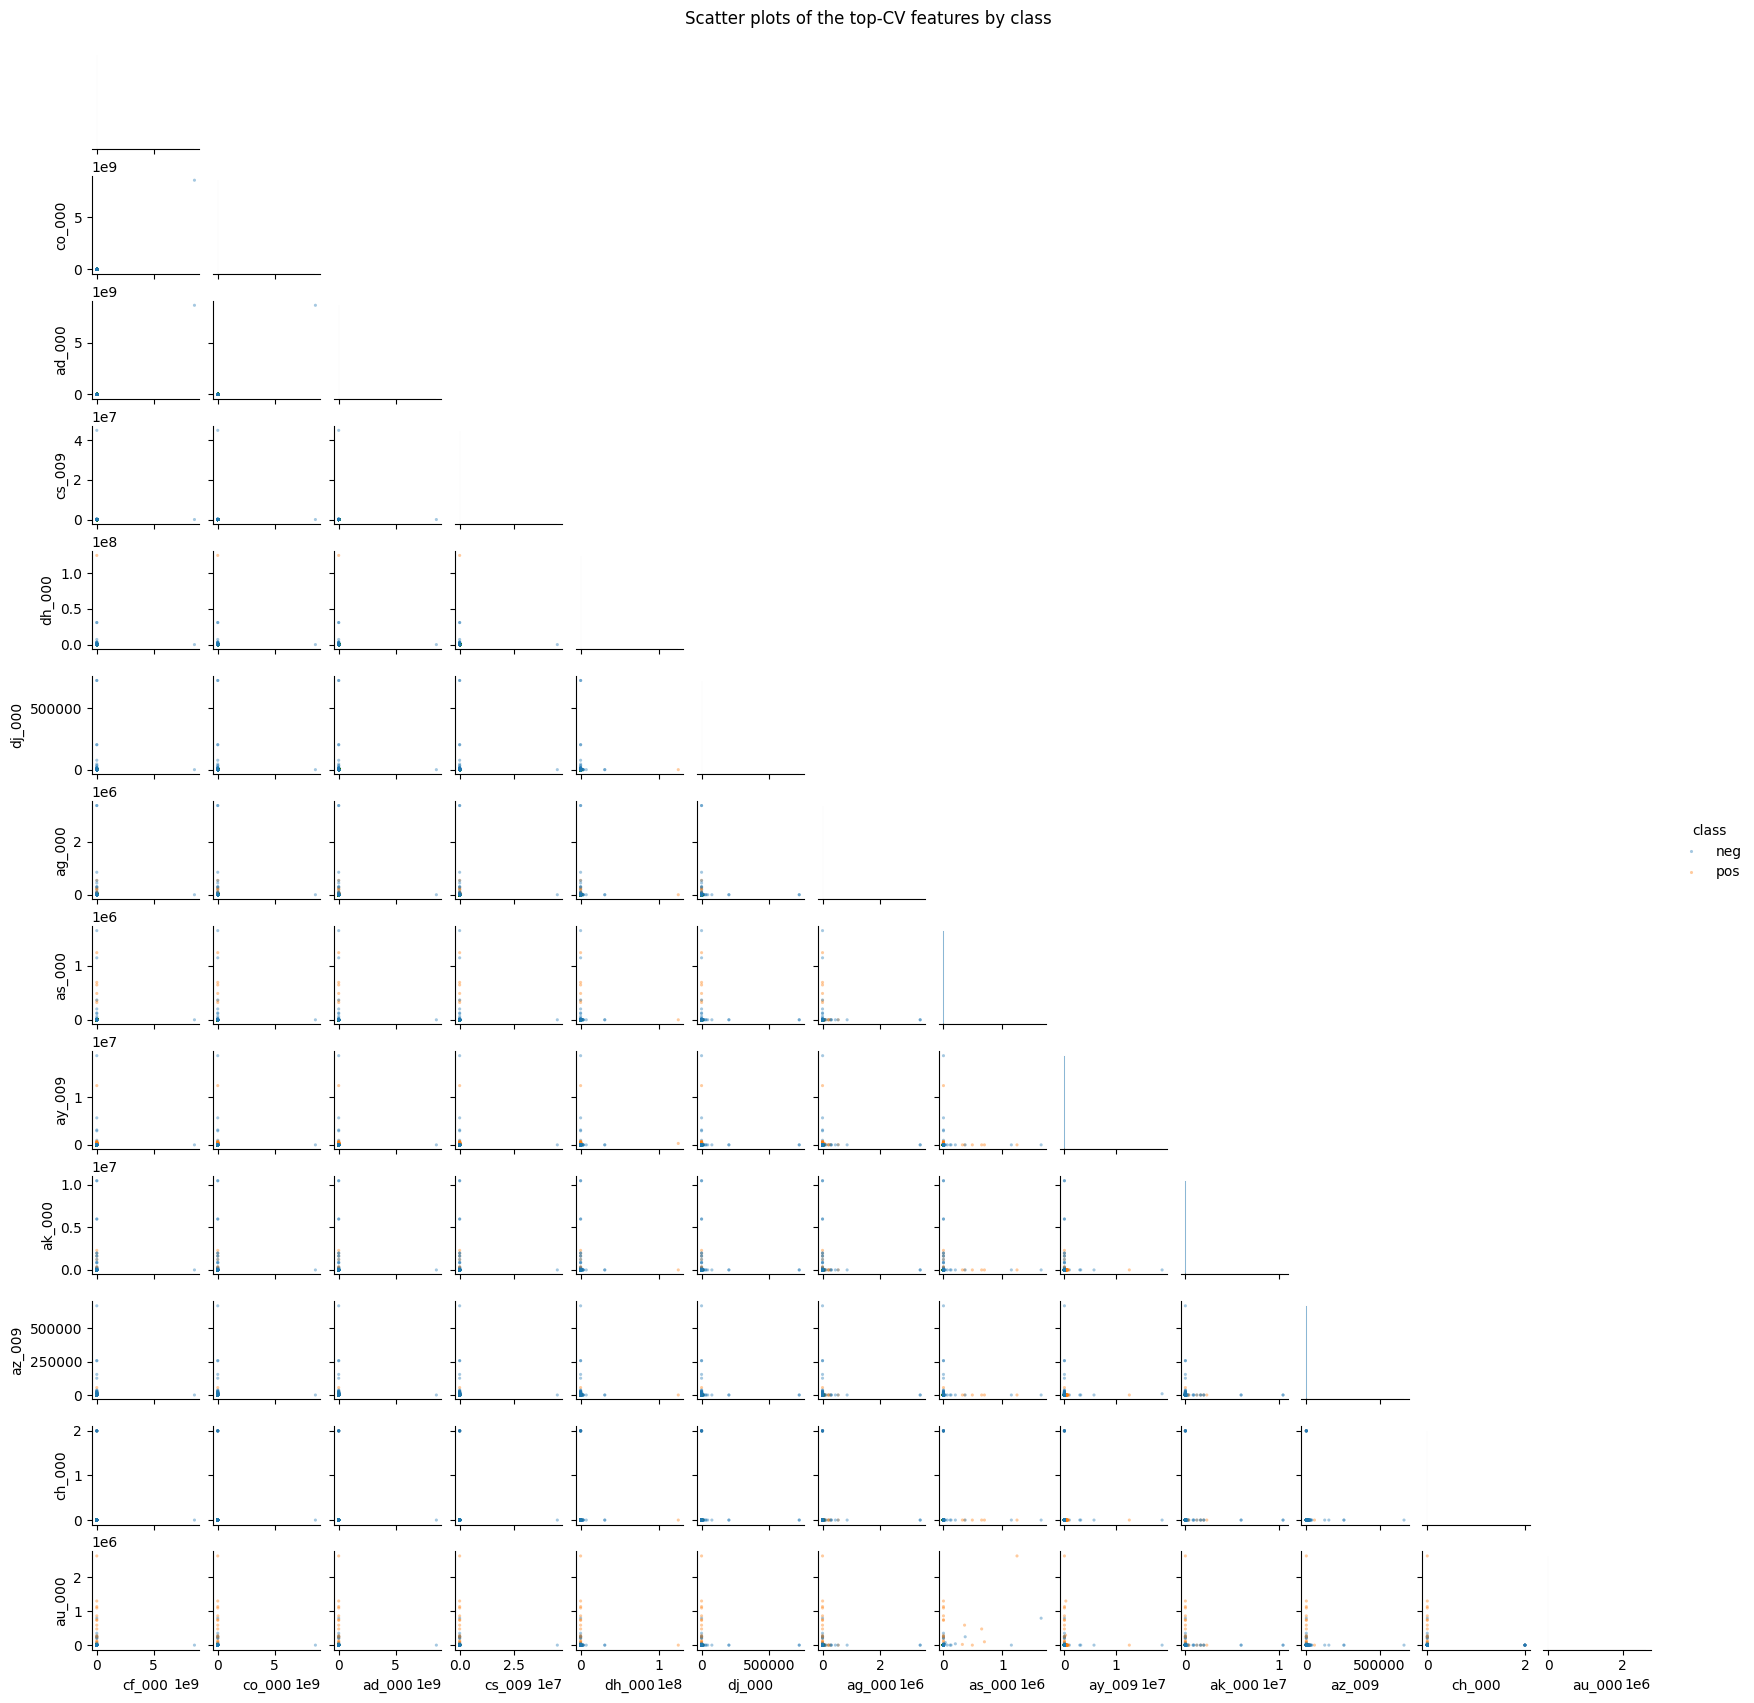

In [10]:
plot_df = X_train[top_cv].copy()
plot_df["class"] = train["class"]

g = sns.pairplot(plot_df, hue="class", hue_order=["neg", "pos"], corner=True,
                 plot_kws={"s": 5, "alpha": 0.4, "linewidth": 0}, diag_kind="hist", height=1.3)
g.fig.suptitle("Scatter plots of the top-CV features by class", y=1.01)
plt.show()

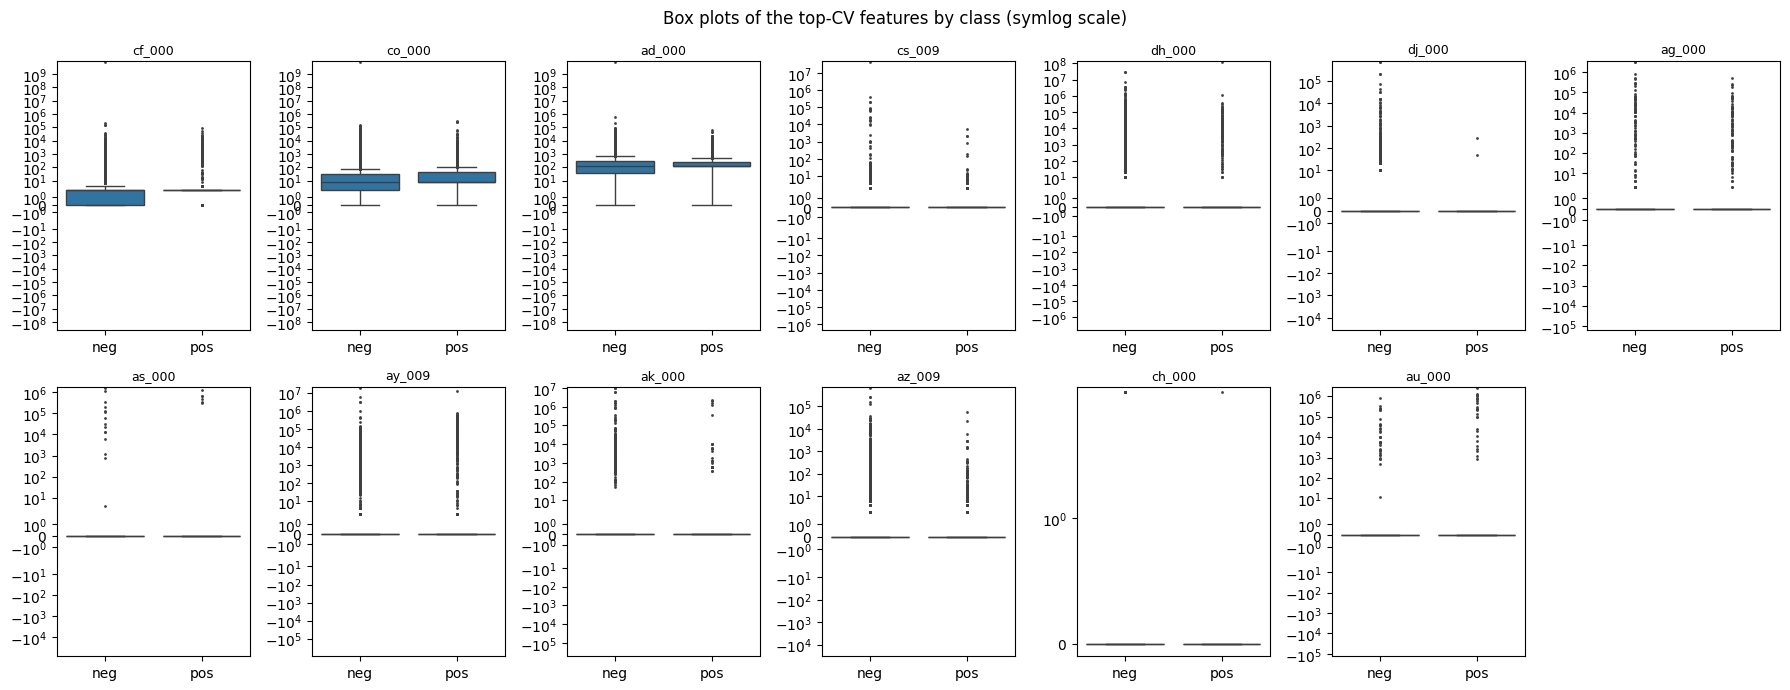

In [11]:
fig, axes = plt.subplots(2, 7, figsize=(18, 7))
for ax, col in zip(axes.flat, top_cv):
    sns.boxplot(x=plot_df["class"], y=plot_df[col], order=["neg", "pos"], ax=ax, fliersize=1)
    ax.set_yscale("symlog")
    ax.set_title(col, fontsize=9); ax.set_xlabel(""); ax.set_ylabel("")
axes.flat[-1].axis("off")
plt.suptitle("Box plots of the top-CV features by class (symlog scale)")
plt.tight_layout(); plt.show()

Can you draw conclusions about significance of those features, just by the scatter plots?
- No. Some features (ex. cf_000, co_000, ad_000) show the positive class shifted toward higher values. However, most features are almost all 0 with a few large outliers, and the 1,000 positives are mostly buried under the 59,000 negatives. Each plot also only shows one or two features at a time, so it can’t tell us whether a feature still matters once the others are included. Significance has to come from a fitted model.

v. positive and negative data

In [12]:
print(y_train.value_counts().rename({0: "neg", 1: "pos"}))
print(f"positive share: {y_train.mean():.2%}")

class
neg    59000
pos     1000
Name: count, dtype: int64
positive share: 1.67%


Yes, the data set is very imbalanced. Only about 1.7% of the training data is positive (59 negatives for every positive).

In [13]:
def report(model, X_tr, y_tr, X_te, y_te, title):
    rows = []
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    for i, (name, X, y) in enumerate([("train", X_tr, y_tr), ("test", X_te, y_te)]):
        prob = model.predict_proba(X)[:, 1]
        pred = model.predict(X)
        cm = confusion_matrix(y, pred)
        print(f"{name} confusion matrix (rows = actual neg/pos, cols = predicted neg/pos):")
        print(cm, "\n")
        auc = roc_auc_score(y, prob)
        rows.append({"set": name, "AUC": auc, "misclassification": 1 - accuracy_score(y, pred)})
        fpr, tpr, _ = roc_curve(y, prob)
        ax[i].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
        ax[i].plot([0, 1], [0, 1], "--", c="gray")
        ax[i].set(title=f"{title}: {name} ROC", xlabel="false positive rate", ylabel="true positive rate")
        ax[i].legend(loc="lower right")
    plt.tight_layout(); plt.show()
    return pd.DataFrame(rows).set_index("set")

### 1c. train random forest  

train confusion matrix (rows = actual neg/pos, cols = predicted neg/pos):
[[59000     0]
 [    0  1000]] 

test confusion matrix (rows = actual neg/pos, cols = predicted neg/pos):
[[15607    18]
 [  104   271]] 



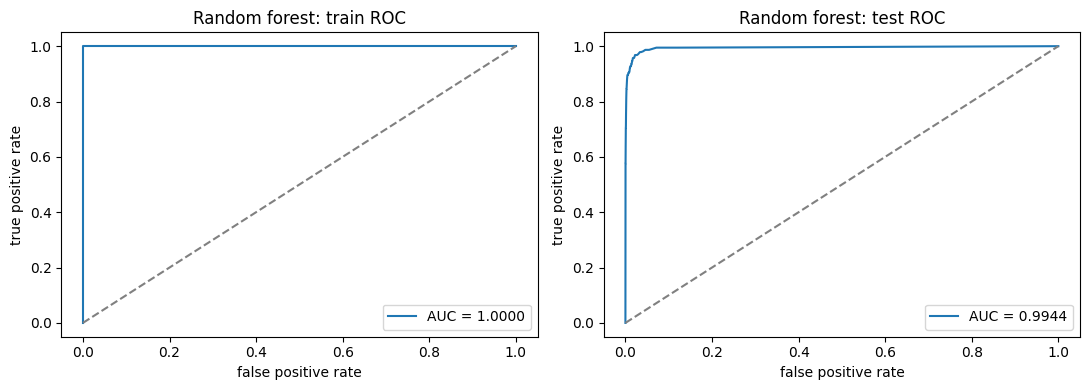

,AUC,misclassification
set,,
train,1.000000,0.000000
test,0.994377,0.007625


OOB error: 0.0059 | test error: 0.0076


In [14]:
rf = RandomForestClassifier(n_estimators=200, oob_score=True, n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(X_train, y_train)

rf_results = report(rf, X_train, y_train, X_test, y_test, "Random forest")
display(rf_results)
print(f"OOB error: {1 - rf.oob_score_:.4f} | test error: {rf_results.loc['test', 'misclassification']:.4f}")

The training set is fit perfectly, which is normal for a random forest, so the training error isn't useful. The OOB error (0.59%) is a much better estimate and is close to the test error (0.76%). The test confusion matrix shows the catch: overall error is low mostly because the model is great at the negative class, but it still misses 104 of the 375 positive trucks (about 28%).

### 1d. random forest with class imbalance compensation

Common ways to handle class imbalance in random forests:
- class weights: bold text make misclassifying the rare class cost more when choosing splits and leaf votes (weighted random forest)
- balanced random forest: each tree's bootstrap sample is drawn so both classes are equally represented (undersampling the majority class)
- resampling the training data first (ex. SMOTE or random oversampling)
- moving the decision threshold below 0.5

I use class weights with `class_weight="balanced_subsample"`, which reweights each tree's bootstrap sample so both classes count equally.

train confusion matrix (rows = actual neg/pos, cols = predicted neg/pos):
[[59000     0]
 [    0  1000]] 

test confusion matrix (rows = actual neg/pos, cols = predicted neg/pos):
[[15609    16]
 [  159   216]] 



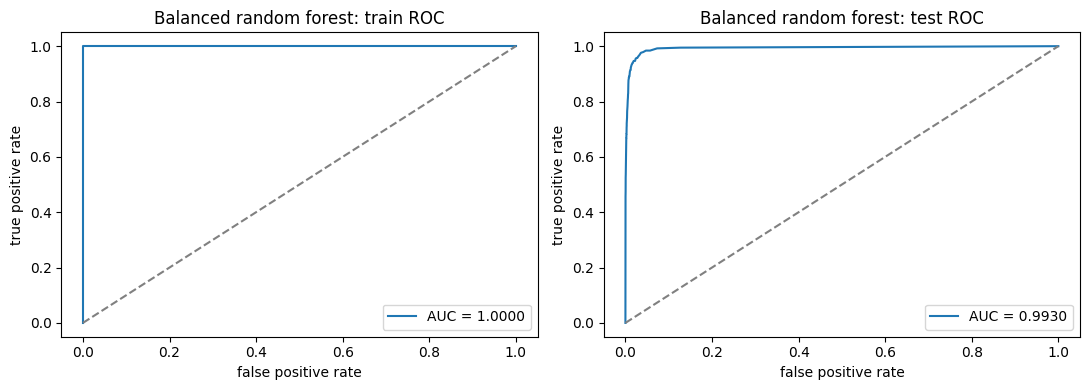

,AUC,misclassification
set,,
train,1.00000,0.000000
test,0.99304,0.010938


OOB error: 0.0080 | test error: 0.0109


In [15]:
rf_bal = RandomForestClassifier(n_estimators=200, oob_score=True, n_jobs=-1, random_state=RANDOM_STATE,
                                class_weight="balanced_subsample")
rf_bal.fit(X_train, y_train)

rf_bal_results = report(rf_bal, X_train, y_train, X_test, y_test, "Balanced random forest")
display(rf_bal_results)
print(f"OOB error: {1 - rf_bal.oob_score_:.4f} | test error: {rf_bal_results.loc['test', 'misclassification']:.4f}")

Comparison with 1c: compensating for imbalance did not help here. On the test set the balanced forest catches fewer failing trucks (219 of 375 vs 271), its test error is higher (1.08% vs 0.76%), and AUC is about the same (0.993 vs 0.994). Random forest trees are grown until the leaves are pure, so reweighting the classes barely changes the splits or the leaf votes. Stronger fixes would be balanced bootstrap sampling, limiting tree depth / leaf size, or lowering the 0.5 threshold. The OOB error (0.77%) is again close to the test error.

### 1e. XGBoost with L1 penalty (no class imbalance compensation)


In [22]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
alpha_grid = [0, 0.01, 0.1, 1, 10]

xgb = XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, tree_method="hist",
                    objective="binary:logistic", eval_metric="logloss",
                    random_state=RANDOM_STATE, n_jobs=-1)

xgb_search = GridSearchCV(xgb, {"reg_alpha": alpha_grid}, cv=skf,
                          scoring={"auc": "roc_auc", "acc": "accuracy"}, refit="auc", n_jobs=1)
xgb_search.fit(X_train, y_train)

xgb_cv = pd.DataFrame({"alpha": alpha_grid,
                       "cv_auc": xgb_search.cv_results_["mean_test_auc"],
                       "cv_error": 1 - xgb_search.cv_results_["mean_test_acc"]})
display(xgb_cv)
best = xgb_search.best_index_
print("best alpha:", xgb_search.best_params_["reg_alpha"])

,alpha,cv_auc,cv_error
0,0.00,0.988421,0.006183
1,0.01,0.988706,0.006000
2,0.10,0.988421,0.006117
3,1.00,0.989376,0.006167
4,10.00,0.989391,0.007017


best alpha: 10


train confusion matrix (rows = actual neg/pos, cols = predicted neg/pos):
[[58960    40]
 [  160   840]] 

test confusion matrix (rows = actual neg/pos, cols = predicted neg/pos):
[[15599    26]
 [  104   271]] 



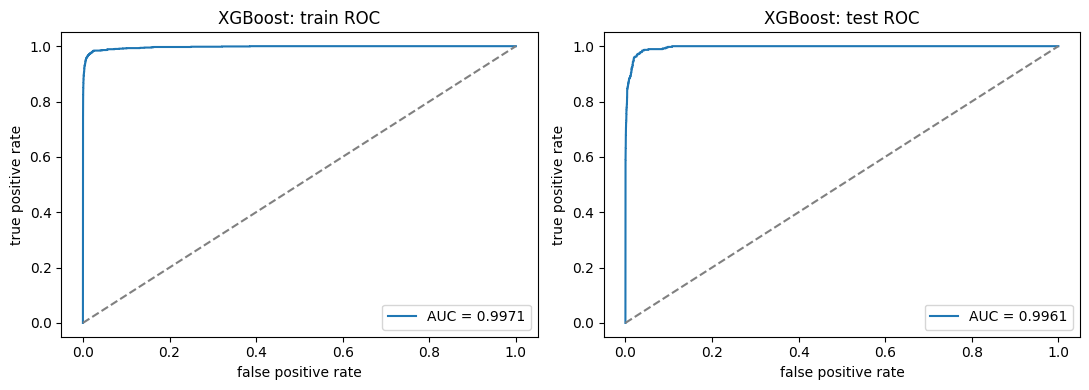

,AUC,misclassification
set,,
train,0.997058,0.003333
test,0.996050,0.008125


5-fold CV error: 0.0070 | test error: 0.0081


In [17]:
xgb_results = report(xgb_search.best_estimator_, X_train, y_train, X_test, y_test, "XGBoost")
display(xgb_results)
print(f"5-fold CV error: {xgb_cv.loc[best, 'cv_error']:.4f} | test error: {xgb_results.loc['test', 'misclassification']:.4f}")

CV picks α = 10, even though CV AUC is almost flat across α. The 5-fold CV error (0.70%) is close to, and slightly lower than, the test error (0.81%). XGBoost has the highest test AUC so far (0.996), but like the uncompensated random forest, it still misses 104 of the 375 failing trucks in the test set.

### 1f. XGBoost with SMOTE

The right way to use SMOTE with CV is to oversample only the training folds so that the validation fold stays as real data. If SMOTE is applied before splitting, synthetic points end up in the validation folds and the CV error looks better than it really is. Putting SMOTE and XGBoost in one imblearn pipeline handles this automatically. SMOTE is applied to the full training set (no downsampling).

In [18]:
smote_pipe = ImbPipeline([
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("xgb", XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4, tree_method="hist",
                          objective="binary:logistic", eval_metric="logloss",
                          random_state=RANDOM_STATE, n_jobs=-1)),
])

smote_search = GridSearchCV(smote_pipe, {"xgb__reg_alpha": alpha_grid}, cv=skf,
                            scoring={"auc": "roc_auc", "acc": "accuracy"}, refit="auc", n_jobs=1)
smote_search.fit(X_train, y_train)

smote_cv = pd.DataFrame({"alpha": alpha_grid,
                         "cv_auc": smote_search.cv_results_["mean_test_auc"],
                         "cv_error": 1 - smote_search.cv_results_["mean_test_acc"]})
display(smote_cv)
best_s = smote_search.best_index_
print("best alpha:", smote_search.best_params_["xgb__reg_alpha"])

,alpha,cv_auc,cv_error
0,0.00,0.987324,0.009517
1,0.01,0.987972,0.009317
2,0.10,0.987406,0.009133
3,1.00,0.986781,0.009200
4,10.00,0.987499,0.010383


best alpha: 0.01


train confusion matrix (rows = actual neg/pos, cols = predicted neg/pos):
[[58775   225]
 [   54   946]] 

test confusion matrix (rows = actual neg/pos, cols = predicted neg/pos):
[[15468   157]
 [   41   334]] 



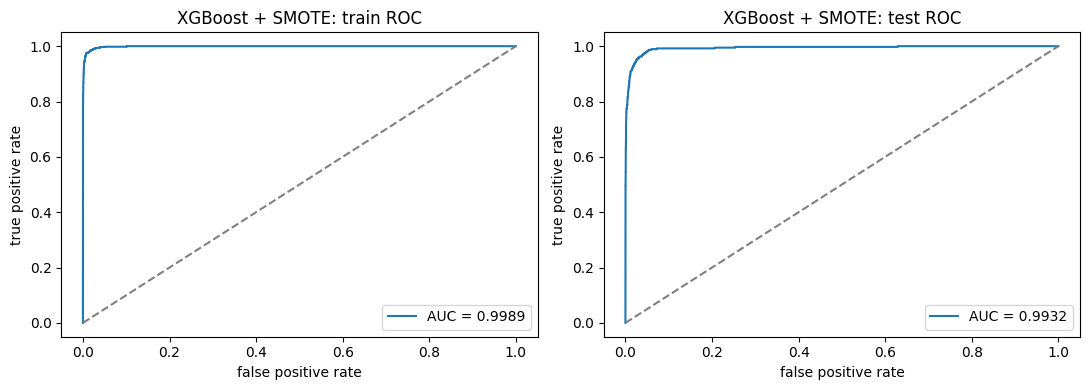

,AUC,misclassification
set,,
train,0.998866,0.004650
test,0.993185,0.012375


5-fold CV error: 0.0093 | test error: 0.0124


In [19]:
smote_results = report(smote_search.best_estimator_, X_train, y_train, X_test, y_test, "XGBoost + SMOTE")
display(smote_results)
print(f"5-fold CV error: {smote_cv.loc[best_s, 'cv_error']:.4f} | test error: {smote_results.loc['test', 'misclassification']:.4f}")

Comparing the uncompensated model:

- SMOTE catches many more failing trucks: *34 of 375 (89%) in the test set vs 271 (72%) without it.
- The trade-off is more false alarms (157 vs 26), so overall test error goes up (1.24% vs 0.81%) and AUC is slightly lower (0.993 vs 0.996).
- The 5-fold CV error (0.93%) is again a bit lower than the test error (1.24%).

Misclassification rate makes SMOTE look worse, but it mostly rewards predicting negative. For this problem, missing a failing truck is  worse than an extra check. The data description uses a cost of 500 for a missed failure and 10 for a false alarm, so the test cost is 26×10 + 104×500 = 52,260 without SMOTE vs 157×10 + 41×500 = 22,070 with SMOTE. By that measure SMOTE more than halves the cost.

### 2. ISLR 6.6.3

As s increases from 0, the lasso constraint loosens and the model becomes more flexible (at s = 0 all β = 0; for large s it becomes least squares).

a. Training RSS: iv. steadily decreases. More flexibility always lets the model fit the training data at least as well.

b. Test RSS: ii. decreases initially, then eventually increases in a U shape. At first the extra flexibility reduces bias and test error drops, but eventually the model overfits.

c. Variance: iii. steadily increases. At s = 0 the model is constant (no variance); as s grows the coefficients depend more on the specific training data.

d. Squared bias: iv. steadily decreases. A more flexible model can get closer to the true relationship.

e. Irreducible error: v. remains constant. It comes from the noise ε and doesn't depend on the model. bold text

### 3. ISLR 6.6.5

Setup: x11 = x12 = x1 and x21 = x22 = x2. Since x1 + x2 = 0 and y1 + y2 = 0, we get x2 = -x1 and y2 = -y1.

a. Ridge: minimize
(y1 - b1*x11 - b2*x12)^2 + (y2 - b1*x21 - b2*x22)^2 + λ(b1^2 + b2^2)

b. Plugging in the setup, both squared terms are the same, so we minimizeqa
2(y1 - (b1 + b2)x1)^2 + λ(b1^2 + b2^2)

Taking the derivative with respect to b1 and b2 and setting each to 0:
- for b1: -4x1(y1 - (b1 + b2)x1) + 2λ*b1 = 0
- for b2: -4x1(y1 - (b1 + b2)x1) + 2λ*b2 = 0

The first part is the same in both, so 2λ*b1 = 2λ*b2, which means b1 = b2 (since λ > 0).

c. Lasso: minimize
(y1 - b1*x11 - b2*x12)^2 + (y2 - b1*x21 - b2*x22)^2 + λ(|b1| + |b2|)
which here becomes 2(y1 - (b1 + b2)x1)^2 + λ(|b1| + |b2|)

(d) The squared part only depends on b1 + b2. If b1 and b2 have the same sign, then |b1| + |b2| = |b1 + b2|, so the penalty also only depends on the sum. So once we find the best sum b1 + b2 = s, any pair of same-sign coefficients that adds up to s gives the same value, and the solution isn't unique.

Solving for the best sum gives s = y1/x1 - λ/(4x1^2) (when s > 0). So the lasso solutions are all points on the line b1 + b2 = s with b1 ≥ 0 and b2 ≥ 0 (or both ≤ 0 if s < 0).

### 4. ISLR 8.4.5

The ten estimates of P(Class is Red | X) are 0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75.

- Majority vote: 6 of the 10 estimates are above 0.5 (0.55, 0.6, 0.6, 0.65, 0.7, 0.75), so 6 trees vote Red and 4 vote Green. The final classification is Red.
- Average probability: the sum is 4.5, so the average is 4.5 / 10 = 0.45 < 0.5. The final classification is Green.

### 5. ISLR 9.7.3

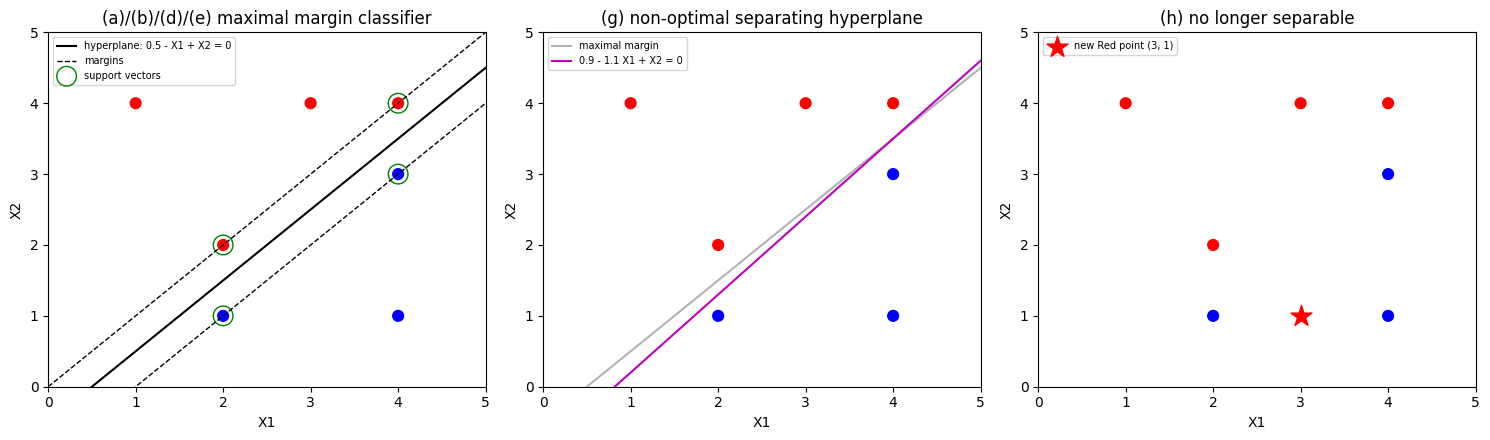

In [20]:
obs = pd.DataFrame({"X1": [3, 2, 4, 1, 2, 4, 4], "X2": [4, 2, 4, 4, 1, 3, 1],
                    "Y": ["Red", "Red", "Red", "Red", "Blue", "Blue", "Blue"]})
colors = obs["Y"].str.lower()
xs = np.linspace(0, 5, 50)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))

# a, b, c, d, e: data, maximal margin hyperplane, margins, support vectors
ax[0].scatter(obs.X1, obs.X2, c=colors, s=60)
ax[0].plot(xs, xs - 0.5, "k-", label="hyperplane: 0.5 - X1 + X2 = 0")
ax[0].plot(xs, xs - 1, "k--", lw=1, label="margins")
ax[0].plot(xs, xs, "k--", lw=1)
sv = obs.iloc[[1, 2, 4, 5]]
ax[0].scatter(sv.X1, sv.X2, s=200, facecolors="none", edgecolors="green", label="support vectors")
ax[0].set_title("(a)/(b)/(d)/(e) maximal margin classifier")

# g. a separating but non-optimal hyperplane
ax[1].scatter(obs.X1, obs.X2, c=colors, s=60)
ax[1].plot(xs, xs - 0.5, "k-", alpha=0.3, label="maximal margin")
ax[1].plot(xs, 1.1 * xs - 0.9, "m-", label="0.9 - 1.1 X1 + X2 = 0")
ax[1].set_title("(g) non-optimal separating hyperplane")

# h. an added red point at (3, 1) makes the classes not separable
ax[2].scatter(obs.X1, obs.X2, c=colors, s=60)
ax[2].scatter([3], [1], c="red", marker="*", s=250, label="new Red point (3, 1)")
ax[2].set_title("(h) no longer separable")

for a in ax:
    a.set(xlim=(0, 5), ylim=(0, 5), xlabel="X1", ylabel="X2")
    a.legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.show()

a. Reference the left plot above.

b. The hyperplane goes halfway between the closest Red and Blue points: between (2, 2) and (2, 1), and between (4, 4) and (4, 3). So it passes through (2, 1.5) and (4, 3.5), which gives X2 = X1 - 0.5, or 0.5 - X1 + X2 = 0.

c. Classify as Red if 0.5 - X1 + X2 > 0, and Blue otherwise. So b0 = 0.5, b1 = -1, b2 = 1.

d. The margin is the distance from the hyperplane to the closest points. For (2, 2): |0.5 - 2 + 2| / sqrt(2) = 0.5 / sqrt(2) ≈ 0.354. The dashed lines in the first plot are the margin edges (X2 = X1 and X2 = X1 - 1).

e. Support vectors: (2, 2) and (4, 4) for Red, (2, 1) and (4, 3) for Blue (circled in green).

f. The 7th point is (4, 1). It's not a support vector and it's far from the margin, so moving it a little doesn't change the hyperplane.

g. The middle plot shows 0.9 - 1.1X1 + X2 = 0. It still separates Red and Blue, but it's closer to some points than the maximal margin hyperplane, so it's not the best one.

h. Add a Red point at (3, 1) (right plot). It sits right between the Blue points (2, 1) and (4, 1), so no straight line can put it on the Red side while keeping both of those on the Blue side. The classes are no longer separable.